In [2]:
import json, os, re, sys, codecs
import matplotlib.pyplot as plt
import pandas
import wget
from korp import *
from eng_corpus import *

In [3]:
def get_total_frequency_for_lemma(lemma, corpus):
    data = get_data_from_github(corpus)
    print("total absolute frequency for", lemma, data[data.lemma == lemma].count()['lemma'])
    print("total relative frequency for", lemma, data[data.lemma == lemma].count()['lemma']/data.count()['lemma'])

In [1]:
!pip install wget
url = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/korp_api.py"
!wget --no-check-certificate $url -O korp.py
url = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/eng_corpus.py"
!wget --no-check-certificate $url -O eng_corpus.py


  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=0787605c8daf2cb512a725ce8fa5b3e3f345fb7e647883706cfeb735bb3b50b1
  Stored in directory: /root/.cache/pip/wheels/8b/f1/7f/5c94f0a7a505ca1c81cd1d9208ae2064675d97582078e6c769
Successfully built wget
--2024-02-06 17:16:12--  https://raw.githubusercontent.com/kannera/keyword_course2021/main/korp_api.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10538 (10K) [text/plain]
Saving to: ‘korp.py’

korp.py             100%[===================>]  10.29K  --.-KB/s    in 0s      

2024-02-06 17:16:12 (63.2 MB/s) - ‘korp.py’ saved [10538/10538]

--2024-02-06 17:16:12--  https://raw.githubusercontent.com/kannera/keyword_course2021/main/eng_corpus.py
Reso

In [ ]:
#this counts full frequency of "medicine" in coca-corpus
#other corpus options are coca, coha and glowbe
get_total_frequency_for_lemma("medicine", "coca")

this done


In [ ]:
#here corpus and lemma are set
corpus = "coha"
lemma = "medicine"

In [ ]:
#this will download the whole corpus and stores it in the memory as a table, where each row represents a token
#the table has 3 common columns: text_id which identifies from which text it is, word which is the actual occurrence of the word in the text
#and lemma which is the lemmatized ("base form") version of the occurrence.
#rest of the columns are devoted to metadata categories describing the text and depend on the corpus
#the second command adds the decade information based on the year columns
#if you change the lemma for queries (ie. looking for frequencies for different word) or from different corpus, you have to run these again
#after changing the values in the block above
data = get_data_from_github(corpus)
data['decade'] = data['year'].apply(lambda x:x[:-1]+"0").astype(int)
data['year'] = data['year'].astype(int)

this done


In [ ]:
#this shows what are the columns in the table
print(data.columns)

Index(['text_id', 'word', 'lemma', 'x1', 'x2', 'len', 'genre', 'year', 'title',
       'author', 'source', 'decade'],
      dtype='object')


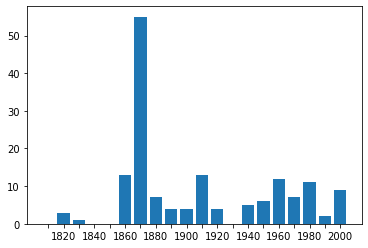

decade
1870    55
1910    13
1860    13
1960    12
1980    11
2000     9
1880     7
1970     7
1950     6
1940     5
Name: lemma, dtype: int64


In [ ]:
#build time series by decade and sort it
#this step only prepares data, it does not have visible output
data_per_decade = data[data.lemma == lemma].groupby("decade").count()['lemma']
for y in data['decade'].unique():
  if y not in data_per_decade.index:
    data_per_decade.loc[y] = 0
data_per_decade = data_per_decade.sort_index()

#the outcome is produced here
#the lines below plot a time series as a bar graph
#the two first are dedicated to getting the x-axis labels show up nicely
plt.bar(list(range(data_per_decade.shape[0])), data_per_decade.values)
x_labels = [str(x) if x in range(1820,2020,20) else "" for x in data_per_decade.index.to_list()]
plt.xticks(ticks=list(range(data_per_decade.shape[0])),labels=x_labels)
plt.show()

#list the top 10 decades
#you can get eg. top 20 by changing the number inside the brackets to '20'
print(data_per_decade.sort_values(ascending=False).head(10))

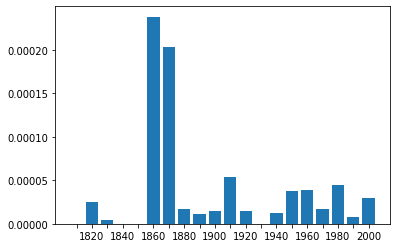

In [ ]:
#what about relative frequencies? If the decade segments are of different sizes, the above results are not much telling
#let's see
#the data is divided by full sizes of the same decade segments
#after that the same plot script is run
data_per_decade = data_per_decade.div(data.groupby('decade').count()['lemma'])
plt.bar(list(range(data_per_decade.shape[0])), data_per_decade.values)
x_labels = [str(x) if x in range(1820,2020,20) else "" for x in data_per_decade.index.to_list()]
plt.xticks(ticks=list(range(data_per_decade.shape[0])),labels=x_labels)
plt.show()

In [ ]:
#let's now move to looking at bars per year
#there seemed to be some dramatic peaks in the two bars above. Now we will see how much these peaks are about specific years.
#this section again only prepares the data
data_per_year = data[data.lemma == lemma].groupby("year").count()['lemma']
for y in data['year'].unique():
  if y not in data_per_year.index:
    data_per_year.loc[y] = 0
data_per_year = data_per_year.sort_index()

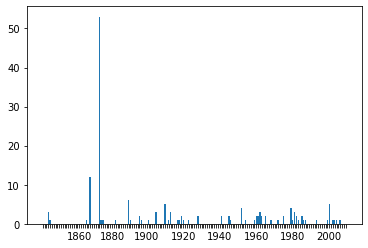

In [ ]:
#the plot is again produced here
plt.bar(list(range(data_per_year.shape[0])), data_per_year.values)
x_labels = [str(x) if x in range(1820,2020,20) else "" for x in data_per_year.index.to_list()]
plt.xticks(ticks=list(range(data_per_year.shape[0])),labels=x_labels)
plt.show()

In [ ]:
#the top year are shown here
print(data_per_year.sort_values(ascending=False).head(10))

year
1873    53
1868    12
1889     6
1910     5
2000     5
1979     4
1952     4
1829     3
1905     3
1962     3
Name: lemma, dtype: int64


In [ ]:
#the top year (1873) is very high peak indeed, let's look at it closer
data_for_year = data[(data.lemma == lemma) & (data.year == 1873)]

In [ ]:
#this shows the top 5 genres
print(data_for_year.groupby('genre').count()['lemma'].sort_values(ascending=False).head(5))

genre
FIC    53
Name: lemma, dtype: int64


In [ ]:
#this shows top 5 books
print(data_for_year.groupby('title').count()['lemma'].sort_values(ascending=False).head(5))

title
Seven and Nine years Among the Camanches and Apaches An  Autobiography    53
Name: lemma, dtype: int64


In [ ]:
#we can look at the actual occurrences with the command get_kwic()
#the first argument (data) should be left as it is, the second is again the studied word
#the first designates the book from which the occurrences are looked from and the fourth one defines how much context is given in words
#here 5 words on each side
get_kwic(data, lemma, "Seven and Nine years Among the Camanches and Apaches An  Autobiography", 5)

man . such be the medicine man of the  
. it seem that the medicine man be averse to
them into heap ; the medicine man stand by and
fund of knowledge concerning vegetable medicine that enable me ,
me how to gather the medicine plant , and where
be the concoction of " medicine , " or mystery
him to " make his medicine ; " to this
until he dream of his medicine . during this time
observe in secure the " medicine " intact . the
sacrifice to a man 's medicine , while day of
be suffer to appease his medicine , when he fancy
as " a man without medicine , " and remain
he lose the charm . medicine thus acquire at the
a man can institute his medicine        
himself by the adoption of medicine capture from the enemy
to protect himself and his medicine ; and again ,
of the material for his medicine ,   often take
the assistant of the great medicine man , i find
council . bloody arm 's medicine be no long good
and he will enter the medicine lodge so that he
place ; and may his medicine be good an

In [ ]:
#Now we move on to comparing two words
#compare two words:
lemmaA = "society"
lemmaB = "state"
corpus = "coha"

In [ ]:
#all of the steps from earlier phase are repeated, but this time for two words in parallel
data = get_data_from_github(corpus)
data['decade'] = data['year'].apply(lambda x:x[:-1]+"0").astype(int)
data['year'] = data['year'].astype(int)

this done


In [ ]:
data_per_decade_A = data[data.lemma == lemmaA].groupby("decade").count()['lemma']
data_per_decade_B = data[data.lemma == lemmaB].groupby("decade").count()['lemma']
for y in data['decade'].unique():
  if y not in data_per_decade_A.index:
    data_per_decade_A.loc[y] = 0
  if y not in data_per_decade_B.index:
    data_per_decade_B.loc[y] = 0
data_per_decade_A = data_per_decade_A.sort_index()
data_per_decade_B = data_per_decade_B.sort_index()

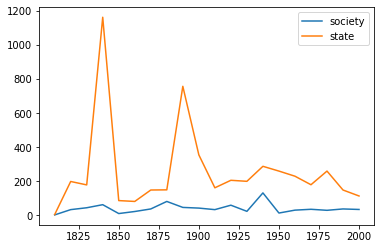

In [ ]:
plt.plot(data_per_decade_A, label=lemmaA)
plt.plot(data_per_decade_B, label=lemmaB)
plt.legend()

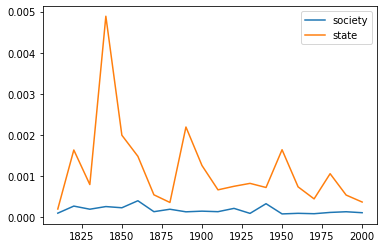

In [ ]:
#how about relative frequencies? So far we have assumed that time segments are of comparable size, but lets now check this out
#we run the above code, but now we add small bits to the end of the first two lines that make the frequencies relative instead of absolute
data_per_decade_A = data[data.lemma == lemmaA].groupby("decade").count()['lemma'].div(data.groupby("decade").count()['lemma'])
data_per_decade_B = data[data.lemma == lemmaB].groupby("decade").count()['lemma'].div(data.groupby("decade").count()['lemma'])
for y in data['decade'].unique():
  if y not in data_per_decade_A.index:
    data_per_decade_A.loc[y] = 0
  if y not in data_per_decade_B.index:
    data_per_decade_B.loc[y] = 0

data_per_decade_A = data_per_decade_A.sort_index()
data_per_decade_B = data_per_decade_B.sort_index()

plt.plot(data_per_decade_A, label=lemmaA)
plt.plot(data_per_decade_B, label=lemmaB)
plt.legend()
#what are some possible reasons for a) systematic differences between the words b) some of the peaks in each

In [ ]:
#how about two words in genres? let's get the relative frequencies right away
genres_A = data[(data.lemma == lemmaA)].groupby('genre').count()['lemma'].div(data.groupby('genre').count()['lemma'])
genres_B = data[(data.lemma == lemmaB)].groupby('genre').count()['lemma'].div(data.groupby('genre').count()['lemma'])
combined_genres = pandas.concat([genres_A, genres_B], axis=1, )
combined_genres.columns = [lemmaA, lemmaB]
combined_genres['state to society'] = combined_genres['state'].div(combined_genres['society'])
print(combined_genres)

        society     state  state to society
genre                                      
FIC    0.000079  0.000196          2.479592
MAG    0.000280  0.001234          4.403175
NEWS   0.000165  0.002266         13.770270
NF     0.000275  0.002853         10.376147
